<a href="https://colab.research.google.com/github/w4bo/AA2627-unibo-dcai/blob/main/slides/lab-01-automl.ipynb" target="_parent"><img src="img/colab-badge.svg" alt="Open In Colab"/></a>

---
title: "AutoML"
bibliography:
  - refs/refs.bib
---

# The Problem: Hyperparameter Optimization

A learning algorithm fits **parameters** (for example, regression coefficients) from data.

**Hyperparameters** configure that fitting process: regularization strength, tree depth, or learning rate.

Hyperparameter optimization is the process of finding the best set of hyperparameters. Given: 

- Training data $D_{\mathrm{tr}}$;
- A learning algorithm $A$ and a target $\mathcal L$;
- A hyperparameter search space $\Lambda$.

It solves

$$\lambda^* \in \arg\min_{\lambda\in\Lambda} f(\lambda), \qquad
f(\lambda)=\mathcal{L}_{D_{\mathrm{val}}}\!\left(A_\lambda(D_{\mathrm{tr}})\right).$$

Here $\mathcal L$ is a validation loss; for classification accuracy we can minimize $1-Accuracy$.

# HPO as an Optimizer–Learning-System Loop

![Optimizer proposes a configuration; the learning system trains and validates it and returns a loss. Source: Hutter and Vanschoren AutoML tutorial.](img/hpo.png)

The learning system fits model parameters.

- E.g., Neural network: connection weights and biases.

The optimizer changes hyperparameters: the distribution and bounds encode assumptions.

- E.g., Neural network: layers, activation functions, learning rate.
- Choose *target*, *metric*, and *hyperparameter* ranges before running the optimizer. 
- **A poor search space can defeat any optimizer**.



# HPO as an Optimizer–Learning-System Loop

![Example of a hyperparameter optimization loop.](img/rf_hpo.svg)

In [37]:
#| echo: false
# Install only packages missing from the current runtime.
import importlib.util
import subprocess
import sys

required_packages = ["flaml", "matplotlib", "numpy", "pandas", "scipy", "sklearn"]
missing_packages = [pkg for pkg in required_packages if importlib.util.find_spec(pkg) is None]

# Check AutoML runtime extras before importing FLAML, avoiding a cached
# partial import when a base installation needs additional dependencies.
if any(importlib.util.find_spec(pkg) is None for pkg in ["xgboost", "lightgbm"]):
    if "flaml" not in missing_packages:
        missing_packages.append("flaml")

if missing_packages:
    pip_names = []
    for pkg in missing_packages:
        if pkg == "sklearn":
            pip_names.append("scikit-learn")
        elif pkg == "flaml":
            pip_names.append("flaml[automl]")
        else:
            pip_names.append(pkg)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *pip_names])

time_budget = 30  # seconds per main FLAML run; use 5 for a quick smoke run


In [38]:
#| echo: false
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import (
    GridSearchCV,
    HalvingRandomSearchCV,
    PredefinedSplit,
    RandomizedSearchCV,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")


In [39]:
#| echo: false
def evaluate_classifier(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    return {
        "accuracy": accuracy_score(y_eval, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_eval, y_pred),
        "f1": f1_score(y_eval, y_pred),
    }


# FLAML minimizes loss; log balanced accuracy alongside it.
def flaml_balanced_accuracy(X_val, y_val, estimator, *args, **kwargs):
    score = balanced_accuracy_score(y_val, estimator.predict(X_val))
    return 1 - score, {"balanced_accuracy": score}


# Get the Dataset

Adult Census Income is downloaded directly from the [UCI repository](https://archive.ics.uci.edu/dataset/2/adult), without OpenML.

In [ ]:
#| echo: false
def load_adult_income(n_rows=8000):
    df = pd.read_csv("https://archive.ics.uci.edu/static/public/2/data.csv", na_values="?", skipinitialspace=True,).dropna()
    df.columns = [c.strip().lower().replace("-", "_") for c in df.columns]
    df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
    df = df.sample(n=min(n_rows, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)
    return df, "UCI Adult Census Income"

adult_df, adult_source = load_adult_income()
adult_df.head()


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,28,Private,319768,Masters,14,Married-civ-spouse,Sales,Husband,White,Male,0,0,45,France,>50K
1,60,Private,120067,9th,5,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,45,United-States,<=50K
2,43,Private,211517,Some-college,10,Never-married,Adm-clerical,Not-in-family,White,Male,0,1669,45,United-States,<=50K
3,35,State-gov,210866,HS-grad,9,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40,United-States,<=50K
4,36,Private,320811,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States,>50K


# Get the Dataset

In [41]:
adult_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             8000 non-null   int64
 1   workclass       8000 non-null   str  
 2   fnlwgt          8000 non-null   int64
 3   education       8000 non-null   str  
 4   education_num   8000 non-null   int64
 5   marital_status  8000 non-null   str  
 6   occupation      8000 non-null   str  
 7   relationship    8000 non-null   str  
 8   race            8000 non-null   str  
 9   sex             8000 non-null   str  
 10  capital_gain    8000 non-null   int64
 11  capital_loss    8000 non-null   int64
 12  hours_per_week  8000 non-null   int64
 13  native_country  8000 non-null   str  
 14  income          8000 non-null   str  
dtypes: int64(6), str(9)
memory usage: 937.6 KB


In [42]:
#| echo: false
X_cls = adult_df.drop(columns=["income"])
y_cls = (adult_df["income"] == ">50K").astype(int)
assert y_cls.nunique() == 2, "Classification requires two target classes."

X_cls_dev, X_cls_test, y_cls_dev, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cls,
)

X_cls_train, X_cls_val, y_cls_train, y_cls_val = train_test_split(
    X_cls_dev, y_cls_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_cls_dev
)

numeric_cls = X_cls_train.select_dtypes(include=np.number).columns.tolist()
categorical_cls = [c for c in X_cls_train.columns if c not in numeric_cls]


# Set the Target: Balanced Accuracy

In [43]:
adult_df["income"].value_counts(normalize=True).rename("target_share").round(3)

income
<=50K    0.745
>50K     0.255
Name: target_share, dtype: float64

For $C$ classes, balanced accuracy is the mean recall across classes:

- $\mathrm{BA}=\frac{1}{C}\sum_{c=1}^{C}\frac{TP_c}{TP_c+FN_c}$
- For binary classification this is $\frac{\mathrm{sensitivity}+\mathrm{specificity}}{2}$. 

A majority-only classifier can have high ordinary accuracy but balanced accuracy of 0.5 when both classes are present.

# Fixed Random-Forest Baseline

In [44]:
# Fit preprocessing once on training rows; every method receives these same arrays.
classification_preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cls),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cls),
])
preprocess_started = time.perf_counter()
X_train_model = classification_preprocess.fit_transform(X_cls_train)
X_val_model = classification_preprocess.transform(X_cls_val)
preprocess_seconds = time.perf_counter() - preprocess_started
classification_baseline = RandomForestClassifier(
    n_estimators=144,
    max_depth=4,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=1,
)
started = time.perf_counter()
classification_baseline.fit(X_train_model, y_cls_train)
baseline_elapsed = time.perf_counter() - started
classification_baseline_scores = evaluate_classifier(classification_baseline, X_val_model, y_cls_val)
comparison_rows = [{
    "method": "baseline", "classifier": type(classification_baseline).__name__,
    "elapsed_s": baseline_elapsed, **classification_baseline_scores,
}]
pd.DataFrame(comparison_rows).round(3)


,method,classifier,elapsed_s,accuracy,balanced_accuracy,f1
0,baseline,RandomForestClassifier,0.383,0.735,0.783,0.628


# Grid Search: Enumerate a Cartesian Product

![Grid search](https://thumb.wikimedia.org/wikipedia/commons/thumb/b/b6/Hyperparameter_Optimization_using_Grid_Search.svg/1920px-Hyperparameter_Optimization_using_Grid_Search.svg.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail)

# Grid Search: Enumerate a Cartesian Product

For each of $d$ hyperparameters, choose a set of values $X_j$.

**Grid search** evaluates $N_{\mathrm{grid}}=\prod_{j=1}^d |X_j|$ configurations.

> For a random forest, 4 depths × 3 leaf sizes × 5 tree counts means 60 candidates, or 300 fits with 5-fold CV.

- Resolution is fixed by the grid: values between grid points are never tried.
- Adding an unimportant dimension multiplies the work.

```python
param_grid = {"max_depth": [2, 8, 24], "min_samples_leaf": [1, 5, 20]}
GridSearchCV(rf_estimator, param_grid, cv=holdout, scoring="balanced_accuracy")
```

# Random Search: Sample Configurations

![Random search](https://thumb.wikimedia.org/wikipedia/commons/thumb/7/74/Hyperparameter_Optimization_using_Random_Search.svg/1920px-Hyperparameter_Optimization_using_Random_Search.svg.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=thumbnail)


# Random Search: Sample Configurations

Choose a sampling distribution $p(\lambda)$, draw and evaluate $N_{rnd}$ independent configurations.

$$\lambda_1,\ldots,\lambda_{N_{rnd}}\sim p(\lambda),\qquad \widehat\lambda\in\arg\min_{\lambda_i}\widehat f(\lambda_i).$$

<details>
<summary>Answer</summary>
Independent trials can be parallelized.
Previous evaluations are ignored, so the search may waste time in unpromising regions.
</details>

```python
param_random = {
    "max_depth": randint(2, 25),
    "min_samples_leaf": randint(1, 21),
}
RandomizedSearchCV(rf_estimator, param_random, n_iter=9, cv=holdout, scoring="balanced_accuracy", random_state=RANDOM_STATE)
```

:::{.fragment}
It does not use earlier scores to propose later candidates. *Pros*? *Cons*?
:::

# Why Can Random Search Work Well?

If only one of two hyperparameters matters, a 3 × 3 grid spends nine trials on only three values of the important parameter.

- Nine random samples could explore nine distinct values of each hyperparameter.
- The advantage grows when a high-dimensional space has only a few influential dimensions.

Let a useful region have probability mass $p$. With independent trials [@bergstra2012random]

$$P(\text{at least one useful configuration in }N\text{ trials})=1-(1-p)^N.$$

- For $p=0.05$, 59 trials give about a 95% chance of hitting that region.
- This is not a guarantee of generalization or of finding the global optimum.

# Why Can Random Search Work Well?

The probability depends on the region's mass under the sampling distribution.

| Independent trials | Hit a region of mass 5% | Hit a region of mass 1% |
| --- | --- | --- |
| 20 | 64% | 18% |
| 60 | 95% | 45% |
| 300 | >99.9% | 95% |

The example depends strongly on the first coordinate. Compare a fixed nine-point grid with 1,000 repetitions of nine random trials.

Grid (9 trials, 3 distinct l1 values): loss = 0.803. Random (9 trials, 9 distinct l1 values): median loss = 0.096
Random search beats the grid in 98% of the repetitions


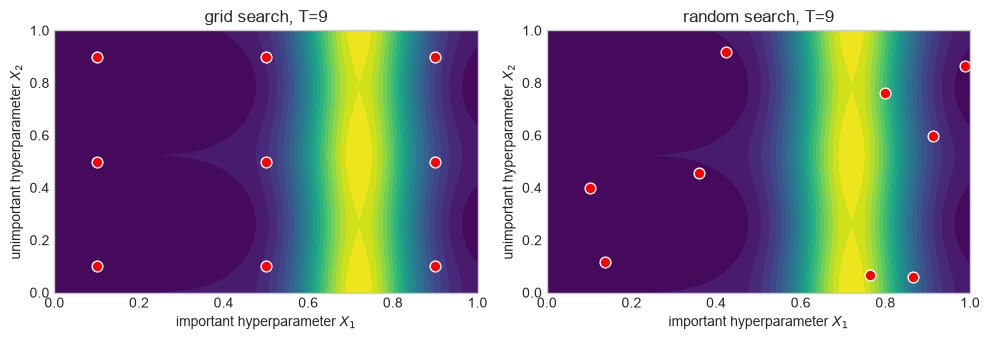

In [45]:
#| echo: false
def toy_objective(l1, l2):
    """Validation loss: depends strongly on l1, weakly on l2. Minimum near l1=0.72."""
    return 1 - np.exp(-((l1 - 0.72) ** 2) / 0.02) + 0.05 * np.sin(6 * l2) ** 2


rng = np.random.default_rng(RANDOM_STATE)
T = 9
side = np.linspace(0.1, 0.9, int(np.sqrt(T)))
G1, G2 = np.meshgrid(side, side)
grid_best = toy_objective(G1, G2).min()

random_best = np.array([
    toy_objective(rng.uniform(0, 1, T), rng.uniform(0, 1, T)).min() for _ in range(1000)
])

print(f"Grid ({T} trials, {len(side)} distinct l1 values): loss = {grid_best:.3f}. Random ({T} trials, {T} distinct l1 values): median loss = {np.median(random_best):.3f}")
print(f"Random search beats the grid in {(random_best < grid_best).mean():.0%} of the repetitions")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
for ax, (title, p1, p2) in zip(axes, [("grid", G1.ravel(), G2.ravel()),
                                      ("random", rng.uniform(0, 1, T), rng.uniform(0, 1, T))]):
    ax.contourf(xx, yy, toy_objective(xx, yy), levels=20, cmap="viridis_r")
    ax.scatter(p1, p2, c="red", edgecolor="white", s=60)
    ax.set_title(f"{title} search, T={T}")
    ax.set_xlabel("important hyperparameter $X_1$")
    ax.set_ylabel("unimportant hyperparameter $X_2$")
plt.tight_layout()
plt.show()

# Example: Four-Parameter Random Forest 

```python
param_grid = {
    "max_depth": [2, 4], "min_samples_leaf": [16, 24], "max_features": [0.15, 1.0], "max_samples": [0.5, 1.0],
}
param_random = {
    "max_depth": randint(2, 5), "min_samples_leaf": randint(1, 25), "max_features": uniform(0.15, 0.85), "max_samples": uniform(0.5, 0.5),
}
```

In [46]:
#| echo: false
# SearchCV uses exactly the existing holdout, with no additional folds.
X_search = np.concatenate([X_train_model, X_val_model])
y_search = np.concatenate([y_cls_train, y_cls_val])
holdout = PredefinedSplit(np.r_[
    np.full(len(y_cls_train), -1), np.zeros(len(y_cls_val), dtype=int)
])
RF_TREES = 144  # Full resource for grid, random search, and halving finalists.
N_RANDOM = 18
rf_estimator = RandomForestClassifier(
    n_estimators=RF_TREES, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1,
)
# Deliberately restricted grid: shallow trees and large leaves can underfit.
param_grid = {
    "max_depth": [2, 4], "min_samples_leaf": [16, 24], "max_features": [0.15, 1.0], "max_samples": [0.5, 1.0],
}
param_random = {
    "max_depth": randint(2, 5), "min_samples_leaf": randint(1, 25), "max_features": uniform(0.15, 0.85), "max_samples": uniform(0.5, 0.5),
}
# refit=False prevents SearchCV from training on the combined train+validation data.
rf_searches = {
    "grid": GridSearchCV(rf_estimator, param_grid, cv=holdout,
                         scoring="balanced_accuracy", refit=False, n_jobs=1, error_score="raise"),
    "random": RandomizedSearchCV(rf_estimator, param_random, n_iter=N_RANDOM, cv=holdout,
        scoring="balanced_accuracy", refit=False, n_jobs=1,
        random_state=RANDOM_STATE, error_score="raise"),
}
rf_search_rows = []


def fit_search(name, search):
    started = time.perf_counter()
    search.fit(X_search, y_search)
    # Fit the selected configuration on TRAINING rows only, at full resource.
    model = clone(rf_estimator).set_params(**search.best_params_)
    model.fit(X_train_model, y_cls_train)
    elapsed = time.perf_counter() - started
    scores = evaluate_classifier(model, X_val_model, y_cls_val)
    row = {
        "method": name, "classifier": type(model).__name__, "elapsed_s": elapsed,
        "evaluations": len(search.cv_results_["params"]),
        "search_trees": sum(p.get("n_estimators", RF_TREES) for p in search.cv_results_["params"]),
        **scores,
    }
    rf_search_rows[:] = [r for r in rf_search_rows if r["method"] != name]
    rf_search_rows.append(row)
    comparison_rows[:] = [r for r in comparison_rows if r["method"] != name]
    comparison_rows.append(row)


for name, search in rf_searches.items():
    fit_search(name, search)
pd.DataFrame(rf_search_rows).round(4)


,method,classifier,elapsed_s,evaluations,search_trees,accuracy,balanced_accuracy,f1
0,grid,RandomForestClassifier,9.4619,16,2304,0.7619,0.8055,0.6564
1,random,RandomForestClassifier,9.8471,18,2592,0.7644,0.8048,0.6570


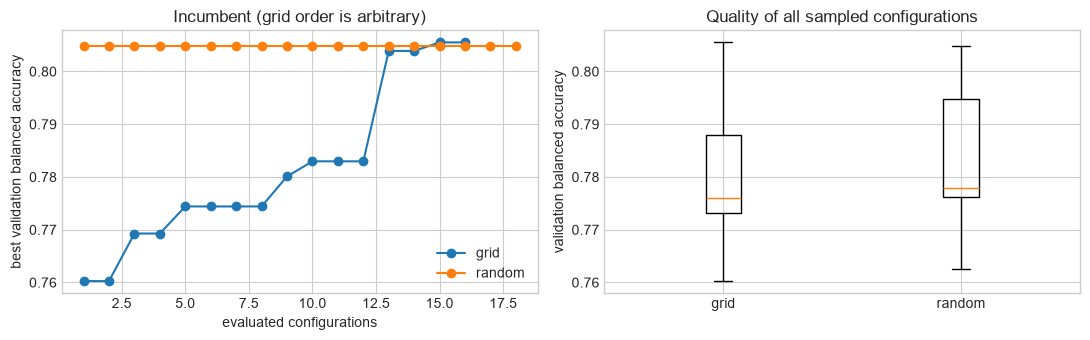

In [ ]:
#| echo: false
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, search in rf_searches.items():
    scores = search.cv_results_["mean_test_score"]
    axes[0].plot(np.arange(1, len(scores) + 1), np.maximum.accumulate(scores), marker="o", label=name)
axes[0].set(xlabel="evaluated configurations", ylabel="best validation balanced accuracy", title="Incumbent (grid order is arbitrary)")
axes[0].legend()
axes[1].boxplot([search.cv_results_["mean_test_score"] for search in rf_searches.values()],
                tick_labels=list(rf_searches))
axes[1].set(ylabel="validation balanced accuracy", title="Quality of sampled configurations")
plt.tight_layout()
plt.show()

# From HPO to AutoML

**Automated Machine Learning (AutoML)** automates choices when building and evaluating an ML solution.

- While HPO fixes the learning algorithm and tunes its settings, AutoML can also choose the algorithm and parts of the pipeline.
- The user defines the task, search space, metric and budget. 

# CASH: Combined Algorithm Selection and Hyperparameter Optimization

Let $\mathcal A=\{A_1,\ldots,A_M\}$ be candidate algorithms and $\Lambda_a$ the hyperparameter space of $A_a$. The **CASH** problem [@thornton2013auto] is

$$ (a^*,\lambda^*)\in\arg\min_{a\in\{1,\ldots,M\},\;\lambda\in\Lambda_a}
\mathcal L_{D_{\mathrm{val}}}\!\left(A_{a,\lambda}(D_{\mathrm{tr}})\right). $$

CASH jointly selects the algorithm and its hyperparameters under a resource budget.

- Its domain is a conditional union $\bigcup_a\{a\}\times\Lambda_a$, rather than one rectangular grid.
- A **root hyperparameter** selects the learner, activating only its associated space $\Lambda_a$.
- E.g., A forest activates tree-related settings; logistic regression activates regularization settings. 

# CASH Search Spaces Are Conditional

The hyperparameter space is a conditional tree or graph, not a Cartesian product of every learner's settings.

| Learner selected at the root | Active hyperparameters |
| --- | --- | 
| Random forest | tree count, tree/leaf constraints | 
| Logistic regression | penalty and regularization strength | 
| Gradient boosting | learning rate, iterations, tree constraints | 

CASH inherits HPO's expensive evaluations and adds learner-level allocation: **which algorithm deserves the next unit of budget?**

- Different learners and configurations have different costs; the answer should depend on observed quality, cost, and remaining resources.

# Search Under a Budget

We have defined what AutoML can choose. How should it spend its search budget?


# The Budget Is Part of the Problem

Budget:

- A **trial/instance/configuration budget** limits the number of candidates.
- A **time budget** limits elapsed time (include preprocessing and search overhead).

They are different: a deep forest can cost much more than a small linear model. 

For a sequential search history $H_N$ a simplified resource constraint is $\sum_{i=1}^N c(A_{\lambda_i},r_i)+c_{\mathrm{overhead}}\le B.$

Here $r_i$ is *fidelity*, $c$ is cost, and $B$ is the total budget.

- The optimizer chooses what to evaluate, at what fidelity (i.e., resource level; for example, sample size or epochs), and when to stop.
- Compare methods with the same data, metric, hardware, and resource accounting. *Why*?

# Bayesian Optimization: Choose the Next Configuration

Random search ignores completed trials. Bayesian optimization uses their results to choose what to try next [@snoek2012practical].

- A **surrogate** predicts validation loss and uncertainty for untested configurations.
- An **acquisition function** balances exploiting promising regions and exploring uncertain ones.
- Evaluate a configuration → update the surrogate → propose the next configuration → repeat until the budget is exhausted.

The surrogate can be a machine learning model, such as a random forest as in SMAC [@hutter2011sequential]. 

- It predicts configuration quality, rather than the dataset's target.

<div></div>
:::: {.columns}
::: {.column width="33%"}
![Grid search](https://thumb.wikimedia.org/wikipedia/commons/thumb/b/b6/Hyperparameter_Optimization_using_Grid_Search.svg/1920px-Hyperparameter_Optimization_using_Grid_Search.svg.png){height=180px}
:::
::: {.column width="33%"}
![Random search](https://thumb.wikimedia.org/wikipedia/commons/thumb/7/74/Hyperparameter_Optimization_using_Random_Search.svg/1920px-Hyperparameter_Optimization_using_Random_Search.svg.png){height=180px}
:::
::: {.column width="33%"}
![Bayesian optimization (TPE)](https://thumb.wikimedia.org/wikipedia/commons/thumb/3/3c/Hyperparameter_Optimization_using_Tree-Structured_Parzen_Estimators.svg/1920px-Hyperparameter_Optimization_using_Tree-Structured_Parzen_Estimators.svg.png){height=180px}
:::
::::


# Bayesian Optimization: Surrogate and Next Evaluation

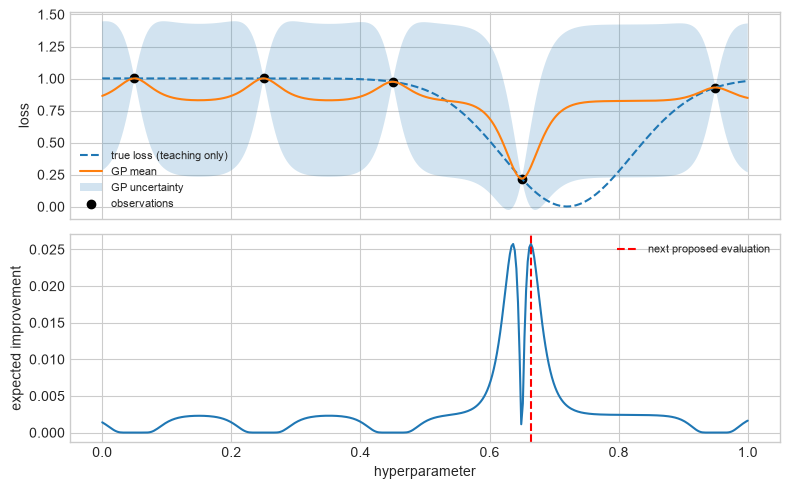

In [48]:
#| echo: false
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern

bo_x = np.array([0.05, 0.25, 0.45, 0.65, 0.95]).reshape(-1, 1)
bo_y = toy_objective(bo_x.ravel(), 0.5)
bo_gp = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0, (0.01, 10)) * Matern(length_scale=0.15, length_scale_bounds=(0.03, 1.0), nu=2.5),
    alpha=1e-6, normalize_y=True, random_state=RANDOM_STATE,
)
bo_gp.fit(bo_x, bo_y)
bo_candidates = np.linspace(0, 1, 400).reshape(-1, 1)
bo_mean, bo_std = bo_gp.predict(bo_candidates, return_std=True)
bo_delta = bo_y.min() - bo_mean - 0.01
bo_z = np.divide(bo_delta, bo_std, out=np.zeros_like(bo_delta), where=bo_std > 0)
bo_ei = np.where(bo_std > 0, bo_delta * norm.cdf(bo_z) + bo_std * norm.pdf(bo_z), np.maximum(bo_delta, 0))
bo_next = int(np.argmax(bo_ei))
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(bo_candidates.ravel(), toy_objective(bo_candidates.ravel(), 0.5), "--", label="true loss (teaching only)")
axes[0].plot(bo_candidates.ravel(), bo_mean, label="GP mean")
axes[0].fill_between(bo_candidates.ravel(), bo_mean - 1.96 * bo_std, bo_mean + 1.96 * bo_std, alpha=0.2, label="GP uncertainty")
axes[0].scatter(bo_x.ravel(), bo_y, color="black", label="observations")
axes[0].set_ylabel("loss")
axes[0].legend(fontsize=8)
axes[1].plot(bo_candidates.ravel(), bo_ei)
axes[1].axvline(bo_candidates[bo_next, 0], color="red", linestyle="--", label="next proposed evaluation")
axes[1].set(xlabel="hyperparameter", ylabel="expected improvement")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Successive Halving: Allocate Resources

Choosing a configuration is one decision, deciding how much resource to spend evaluating it is another.

**Fidelity** is the resource level: for example, fewer training rows or epochs give a cheaper evaluation.

- Successive halving increases resources for the surviving candidates [@jamieson2016nonstochastic].

| Round | Candidates | Resource per candidate | Total resource |
| --- | --- | --- | --- |
| 0 | 18 | 16 trees | 288 trees |
| 1 | 6 | 48 trees | 288 trees |
| 2 | 2 | 144 trees | 288 trees |



# Hyperband: Vary the Starting Allocation

Successive halving fixes the starting allocation: the number of candidates and their initial resource.

- Hyperband varies that tradeoff across several halving brackets [@li2018hyperband].
  - Start many candidates cheaply, or fewer candidates with more resources each.
  - Low-fidelity rankings can be misleading: a model that learns slowly may be discarded too early.
- Low fidelity is useful when it preserves enough of the high-fidelity ranking. 
  - ... It can also discard slow-starting or data-hungry models.

![SVM validation error at increasing MNIST sample sizes. Source: Hutter and Vanschoren AutoML tutorial.](img/fidelity-1.png)



# Multi-Fidelity and Combined Search

![SVM validation error at increasing MNIST sample sizes. Source: Hutter and Vanschoren AutoML tutorial.](img/fidelity-2.png)

# Demo: Successive Halving on the Same Random Forest Space

Compare 18 initial configurations on the same training/validation rows.

- Halving allocates trees over three rounds:
  - Increase tree count: 16 → 48 → 144.
  - Retain approximately one third: 18 → 6 → 2 candidates.
- Random search gives every candidate 144 trees.

In [49]:
halving = HalvingRandomSearchCV(
    rf_estimator, param_random, n_candidates=N_RANDOM, factor=3,
    resource="n_estimators", min_resources=16, max_resources=RF_TREES,
    cv=holdout, scoring="balanced_accuracy", refit=False, n_jobs=1,
    random_state=RANDOM_STATE, error_score="raise",
)
fit_search("halving", halving)

In [50]:
#| echo: false
#| output: false
initial_halving = [
    {k: v for k, v in p.items() if k != "n_estimators"}
    for p, iteration in zip(halving.cv_results_["params"], halving.cv_results_["iter"])
    if iteration == 0
]
pd.DataFrame({
    "round": range(halving.n_iterations_),
    "candidates": halving.n_candidates_,
    "trees_per_candidate": halving.n_resources_,
    "total_search_trees": np.array(halving.n_candidates_) * np.array(halving.n_resources_),
})


,round,candidates,trees_per_candidate,total_search_trees
0,0,18,16,288
1,1,6,48,288
2,2,2,144,288


In [51]:
#| echo: false
search_comparison = pd.DataFrame(rf_search_rows).set_index("method")
display(search_comparison.round(4))
print(f"Halving speedup over random: {search_comparison.loc['random', 'elapsed_s'] / search_comparison.loc['halving', 'elapsed_s']:.2f}x")

,classifier,elapsed_s,evaluations,search_trees,accuracy,balanced_accuracy,f1
method,,,,,,,
grid,RandomForestClassifier,9.4619,16,2304,0.7619,0.8055,0.6564
random,RandomForestClassifier,9.8471,18,2592,0.7644,0.8048,0.6570
halving,RandomForestClassifier,5.0344,26,864,0.7644,0.8048,0.6570


Halving speedup over random: 1.96x


# Budget Questions

1. How many configurations survived each halving round, and how many trees were fitted during search?
2. How much runtime did halving save compared with evaluating the same candidates at full resource?
3. What happened to validation balanced accuracy? Could an early ranking discard the eventual best candidate?


# FLAML: Search and Resource Allocation

FLAML is an AutoML system that selects learners and hyperparameters under a budget [@wang2021flaml].

- **Configuration selection:** like BO, it uses previous results [@wu2021frugal].
- **Resource allocation:** like Hyperband, FLAML adapts resource allocation.
    - Adjust training sample size.
    - Allocate time across learners using observed cost and improvement.

In [52]:
from flaml import AutoML
classification_automl = AutoML()
classification_started_at = time.perf_counter()
classification_automl.fit(
    X_train=X_train_model, y_train=y_cls_train,
    X_val=X_val_model, y_val=y_cls_val,
    eval_method="holdout",
    retrain_full=False,
    task="classification", metric=flaml_balanced_accuracy,
    time_budget=time_budget,
    log_file_name=f"flaml_main_classification_balanced_accuracy_{time_budget}s.log", seed=RANDOM_STATE, verbose=1, n_jobs=1,
)
classification_elapsed = time.perf_counter() - classification_started_at
print(f"Selected learner: {classification_automl.best_estimator}; classifier: {type(classification_automl.model.estimator).__name__}")
print("Selected hyperparameters:", classification_automl.best_config)

Selected learner: lgbm; classifier: LGBMClassifier
Selected hyperparameters: {'n_estimators': 34, 'num_leaves': 36, 'min_child_samples': 6, 'learning_rate': np.float64(0.23881309587121854), 'log_max_bin': 7, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.020536646451193807), 'reg_lambda': np.float64(0.02276574312098569)}


# FLAML: Search and Resource Allocation

In [53]:
#| echo: false
classification_automl_scores = evaluate_classifier(classification_automl, X_val_model, y_cls_val)
comparison_rows[:] = [r for r in comparison_rows if r["method"] != "FLAML"]
comparison_rows.append({
    "method": "FLAML", "classifier": type(classification_automl.model.estimator).__name__,
    "elapsed_s": classification_elapsed, **classification_automl_scores,
})
# All scores use the SAME validation rows and encoded columns.
classification_comparison = pd.DataFrame(comparison_rows)[[
    "method", "classifier", "elapsed_s", "accuracy", "balanced_accuracy", "f1"
]].set_index("method")
classification_comparison.round(4)


,classifier,elapsed_s,accuracy,balanced_accuracy,f1
method,,,,,
baseline,RandomForestClassifier,0.3827,0.7350,0.7826,0.6281
grid,RandomForestClassifier,9.4619,0.7619,0.8055,0.6564
random,RandomForestClassifier,9.8471,0.7644,0.8048,0.6570
halving,RandomForestClassifier,5.0344,0.7644,0.8048,0.6570
FLAML,LGBMClassifier,30.0090,0.8712,0.8222,0.7406


# Inspect FLAML's Conditional CASH Space


In [54]:
from flaml.automl.model import RandomForestEstimator
from flaml.automl.task.factory import task_factory
print("Default learners for this run:", classification_automl.estimator_list)

Default learners for this run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']


In [55]:
#| echo: false
def describe_space(space):
    rows = []
    for name, spec in space.items():
        domain = spec["domain"]
        if hasattr(domain, "categories"): values = str(list(domain.categories))
        elif hasattr(domain, "lower") and hasattr(domain, "upper"):
            sampler = domain.get_sampler() if hasattr(domain, "get_sampler") else None
            values = f"[{domain.lower}, {domain.upper}] ({type(sampler).__name__})"
        else: values = str(domain)
        rows.append({"hyperparameter": name, "domain": values, "init_value": spec.get("init_value"), "low_cost_init_value": spec.get("low_cost_init_value")})
    return pd.DataFrame(rows)

In [56]:
describe_space(RandomForestEstimator.search_space(data_size=X_train_model.shape, task=task_factory("classification", X_train_model, y_cls_train)))

,hyperparameter,domain,init_value,low_cost_init_value
0,n_estimators,"[4, 2048] (_LogUniform)",4.000000,4.0
1,max_features,"[0.09901475429766744, 1.0] (_LogUniform)",0.099015,NaN
2,max_leaves,"[4, 2400] (_LogUniform)",4.000000,4.0
3,criterion,"['gini', 'entropy']",NaN,NaN


# Anytime Performance Under a Budget

Define the incumbent curve for completed trials $f^*(\tau)=\min\{f_i:t_i\le\tau\},\qquad \tau\le B.$

- Each trial has a validation loss $f_i$ and a completion time $t_i$.
- The curve shows how quickly the optimizer finds better configurations.

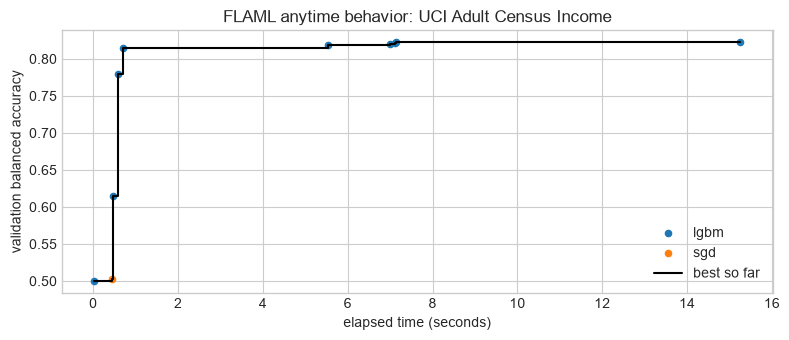

In [57]:
#| echo: false
from flaml.automl.data import get_output_from_log
log_path = f"flaml_main_classification_balanced_accuracy_{time_budget}s.log"
time_history, best_loss_history, loss_history, config_history, _ = get_output_from_log(
    filename=log_path, time_budget=float("inf")
)
learners = [record["Current Learner"] for record in config_history]
fig, ax = plt.subplots(figsize=(8, 3.5))
for learner in sorted(set(learners)):
    idx = [i for i, name in enumerate(learners) if name == learner]
    ax.scatter(np.asarray(time_history)[idx], 1 - np.asarray(loss_history)[idx], s=20, label=learner)
ax.step(time_history, 1 - np.asarray(best_loss_history), where="post", color="black", label="best so far")
ax.set(xlabel="elapsed time (seconds)", ylabel="validation balanced accuracy", title=f"FLAML anytime behavior: {adult_source}")
ax.legend()
plt.tight_layout()
plt.show()

Increasing a budget changes the search opportunity.

- Tradeoff of validation quality and elapsed time: if two budgets give similar validation scores, is the extra compute time justified?
- A system that is excellent after two hours may not be the best choice for an interactive workflow that allows only two minutes.

# From CASH to End-to-End Pipeline Optimization

So far, we fixed data cleaning, category encoding, feature availability, and validation design, then searched over learners. 

- End-to-end pipeline optimization also searches over the **structure and operations** that turn raw data into predictions.

- Describe a pipeline using its conditional settings $\theta\in\Theta_s$ and the steps $\mathcal S(C)$ allowed by constraints $C$.

$$ (s^*,\theta^*)\in\arg\min_{s\in\mathcal S(C),\;\theta\in\Theta_s}
\widehat{\mathcal L}_{\mathrm{val}}\!\left(\operatorname{Fit}(P_{s,\theta},D_{\mathrm{tr}})\right),
\qquad c_{\mathrm{search}}\le B. $$

![End-to-End Pipeline Optimization](./img/phdslides_218.png)

# Why Full Pipeline Search Is Harder

[@giovanelli2021effective] study transformations and combinations of transformations as **pipeline prototypes**.

- E.g., which step types are present and in which order.
- Unfortunately, no pipeline prototype is always best.
    - **Data quality:** deletion, imputation, and feature construction can change who is represented and what the model learns.
    - **Constraints:** accuracy competes with latency, fairness, interpretability, and resource limits; some pipelines are inadmissible even if accurate.
    - **Dependencies:** scaling matters for some learners, not for others.
    - ...
- **Exercise:** discuss admissible orders for feature selection/resampling/imputation.

# MLZero: Agents Build and Repair ML Workflows

[@fang2025mlzero] uses LLM-powered agents to automate workflows across data modalities.

![MLZero](https://project-mlzero.github.io/assets/images/aga-abstract.jpg)

- Agents generate code, execute it, inspect failures, and revise the workflow.
- Memory helps reduce hallucinated or outdated API calls:
  - Semantic memory supplies reusable knowledge.
  - Episodic memory retains earlier attempts and errors.

# Wrap-Up

# What AutoML Automates

AutoML can automate repetitive parts of modeling:

- trying candidate learners;
- allocating trials;
- tuning hyperparameters;
- returning a strong baseline.

# What AutoML Does Not Automate

AutoML does not remove the data-science responsibility for:

- problem formulation;
- target definition;
- leakage checks;
- fairness assessment;
- deployment monitoring;
- deciding whether a model should be used at all.

# Further Reading (BIG's research on this topic)

- HAMLET [@francia2023hamlet].
- AutoClues [@francia2024autoclues].
- AGE-ML [@matteini2026agentic].


# Exercise: Does Data-Centric Solution Help?

Compare three models using **balanced accuracy**:

- Logistic regression with/without numeric standardization.
- FLAML on the same raw and standardized inputs.

Data preparation is provided. Fit the models, compare their scores and times, and explain the effect of standardization.


# Step 1 - Prepare the Inputs

Run the cell below. It reuses the lab's split and preprocessing transformer.

- `X_train` and `X_val` have one-hot encoded categories and unscaled numeric features.
- `y_train` and `y_val` are the corresponding labels.
- Standardization is the only preprocessing change tested in Step 3.
- Leave the test set until Step 5.


In [58]:
import time
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

# Keep the lab's column selection and one-hot encoding; disable numeric scaling.
unscaled_preprocess = clone(classification_preprocess).set_params(num="passthrough")
X_train = unscaled_preprocess.fit_transform(X_cls_train)
X_val = unscaled_preprocess.transform(X_cls_val)
y_train, y_val = y_cls_train, y_cls_val


# Step 2 - Fit the Unscaled Baseline

Fit logistic regression on `X_train` and `y_train`.

- Predict on `X_val` and calculate balanced accuracy.
- Record fit time and any convergence warning.


In [59]:
# Create logistic = LogisticRegression(max_iter=2000, random_state=42).
# Start a timer with time.perf_counter(), then fit on X_train and y_train.
# Save the elapsed time as logistic_seconds.
# Predict with logistic.predict(X_val).
# Save balanced_accuracy_score(y_val, predictions) as logistic_val_ba.
# Print the elapsed time and score; note any convergence warning.


# Step 3 - Standardize Numeric Features

Adult's numeric features have different scales: age is in years, while `fnlwgt` can be in the hundreds of thousands.

- `StandardScaler` subtracts each numeric feature's training mean and divides by its training standard deviation.
- This puts the numeric features on comparable scales for regularized logistic regression.

Run the provided preparation code and fit the same logistic regression settings on `X_train_scaled`.

- Compare validation balanced accuracy, fit time, and convergence with the unscaled baseline.


In [60]:
# Reuse the lab's transformer, which already fits StandardScaler on numeric features.
# It was fitted on training data only, so use transform for both splits.
X_train_scaled = classification_preprocess.transform(X_cls_train)
X_val_scaled = classification_preprocess.transform(X_cls_val)

# Create logistic_scaled = LogisticRegression(max_iter=2000, random_state=42).
# Fit on X_train_scaled and y_train; record scaled_seconds.
# Predict on X_val_scaled and save scaled_val_ba using balanced_accuracy_score.
# Compare score, time, and convergence with the unscaled logistic regression.


# Step 4 - Run AutoML

Run the provided FLAML search on `X_train_scaled` and `X_val_scaled`.

- These are the exact inputs used by the standardized logistic regression.
- Record the selected classifier, validation balanced accuracy, and search time.
- Compare the result with both logistic regressions.


In [61]:
from flaml import AutoML

# Provided: FLAML minimizes loss, so convert balanced accuracy to a loss.
def balanced_accuracy_loss(X_val, y_val, estimator, *args, **kwargs):
    return 1 - balanced_accuracy_score(y_val, estimator.predict(X_val)), {}

automl = AutoML()
started = time.perf_counter()
automl.fit(
    X_train=X_train_scaled, y_train=y_train,
    X_val=X_val_scaled, y_val=y_val,
    task="classification", metric=balanced_accuracy_loss,
    eval_method="holdout", retrain_full=False,
    time_budget=30, n_jobs=1, seed=42, verbose=0,
)
automl_seconds = time.perf_counter() - started
print("Selected classifier:", type(automl.model.estimator).__name__)

# Predict on X_val_scaled and save automl_val_ba using balanced_accuracy_score.
# Compare all three validation scores and their training/search times.


Selected classifier: LGBMClassifier


# Step 5 - Compare and Check Test Scores

Choose your preferred model using validation results, then run the provided test preparation code.

- Evaluate each model once on its matching test inputs.
- Explain whether standardization helped and whether AutoML added further benefit.
- Remember: do not tune after seeing test results.


In [62]:
# Prepare test inputs without refitting either preprocessing transformer.
X_test = unscaled_preprocess.transform(X_cls_test)
X_test_scaled = classification_preprocess.transform(X_cls_test)
y_test = y_cls_test

# Predict with logistic on X_test.
# Predict with logistic_scaled and automl on X_test_scaled.
# Calculate balanced_accuracy_score(y_test, predictions) for each model.
# Put the three models' validation/test scores and elapsed times in a pd.DataFrame.
# Explain the effect of standardization and the extra value, if any, of AutoML.


# Exercise Solution {.scrollable}

<details>
<summary>Show the solution</summary>

The solution also compares FLAML with and without standardization, using a separate 30-second search for each.

- Both searches use the same rows, metric, seed, and default learners.
- Each run repeats model selection, so differences can reflect both scaling and the time-limited search.

```python
import time
import pandas as pd
from flaml import AutoML
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

# Same rows, columns, and category encoding; only numeric scaling changes.
unscaled_preprocess = clone(classification_preprocess).set_params(num="passthrough")
X_train = unscaled_preprocess.fit_transform(X_cls_train)
X_val = unscaled_preprocess.transform(X_cls_val)
X_train_scaled = classification_preprocess.transform(X_cls_train)
X_val_scaled = classification_preprocess.transform(X_cls_val)
y_train, y_val = y_cls_train, y_cls_val

# 1. Unscaled logistic regression. Note any convergence warning.
logistic = LogisticRegression(max_iter=2000, random_state=42)
started = time.perf_counter()
logistic.fit(X_train, y_train)
logistic_seconds = time.perf_counter() - started
logistic_val_ba = balanced_accuracy_score(y_val, logistic.predict(X_val))

# 2. Same settings, with standardized numeric features.
logistic_scaled = LogisticRegression(max_iter=2000, random_state=42)
started = time.perf_counter()
logistic_scaled.fit(X_train_scaled, y_train)
scaled_seconds = time.perf_counter() - started
scaled_val_ba = balanced_accuracy_score(y_val, logistic_scaled.predict(X_val_scaled))

# 3. Compare FLAML on unscaled and standardized inputs with equal search budgets.
def balanced_accuracy_loss(X_val, y_val, estimator, *args, **kwargs):
    return 1 - balanced_accuracy_score(y_val, estimator.predict(X_val)), {}

automl_unscaled = AutoML()
started = time.perf_counter()
automl_unscaled.fit(
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    task="classification", metric=balanced_accuracy_loss,
    eval_method="holdout", retrain_full=False,
    time_budget=30, n_jobs=1, seed=42, verbose=0,
)
automl_unscaled_seconds = time.perf_counter() - started
automl_unscaled_val_ba = balanced_accuracy_score(y_val, automl_unscaled.predict(X_val))

automl = AutoML()
started = time.perf_counter()
automl.fit(
    X_train=X_train_scaled, y_train=y_train,
    X_val=X_val_scaled, y_val=y_val,
    task="classification", metric=balanced_accuracy_loss,
    eval_method="holdout", retrain_full=False,
    time_budget=30, n_jobs=1, seed=42, verbose=0,
)
automl_seconds = time.perf_counter() - started
automl_val_ba = balanced_accuracy_score(y_val, automl.predict(X_val_scaled))

results = pd.DataFrame({
    "approach": ["unscaled logistic", "standardized logistic", "unscaled FLAML", "standardized FLAML"],
    "classifier": [
        type(logistic).__name__, type(logistic_scaled).__name__,
        type(automl_unscaled.model.estimator).__name__, type(automl.model.estimator).__name__,
    ],
    "fit_search_seconds": [
        logistic_seconds, scaled_seconds, automl_unscaled_seconds, automl_seconds,
    ],
    "validation_BA": [
        logistic_val_ba, scaled_val_ba, automl_unscaled_val_ba, automl_val_ba,
    ],
})
print(results.round(4).to_string(index=False))

# This example selects the highest validation BA; justify any time/simplicity tradeoff.
chosen_approach = results.loc[results["validation_BA"].idxmax(), "approach"]
print("Choice before test:", chosen_approach)

# Evaluate once on the corresponding test representations; do not refit.
X_test = unscaled_preprocess.transform(X_cls_test)
X_test_scaled = classification_preprocess.transform(X_cls_test)
y_test = y_cls_test
results["test_BA"] = [
    balanced_accuracy_score(y_test, logistic.predict(X_test)),
    balanced_accuracy_score(y_test, logistic_scaled.predict(X_test_scaled)),
    balanced_accuracy_score(y_test, automl_unscaled.predict(X_test)),
    balanced_accuracy_score(y_test, automl.predict(X_test_scaled)),
]
print(results.round(4).to_string(index=False))
print("Logistic standardization gain (validation, percentage points):", round(100 * (scaled_val_ba - logistic_val_ba), 2))
print("FLAML standardization gain (validation, percentage points):",
      round(100 * (automl_val_ba - automl_unscaled_val_ba), 2))
print("AutoML gain over standardized logistic (validation, percentage points):",
      round(100 * (automl_val_ba - scaled_val_ba), 2))
```
</details>


# References